# Assignment 2 - LSTM Autoencoder Anomaly Detection

Dataset: **Network Intrusion Detection** (`archive/Train_data.csv`).

Each row is one network connection, labelled as `normal` or `anomaly` in the `class` column.
We train LSTM autoencoders only on *normal* traffic. If a row cannot be reconstructed well
(high reconstruction error), we flag it as an anomaly.


## Question 1: LSTM Autoencoder-Based Anomaly Detection

In [1]:
import os

os.environ["TF_XLA_FLAGS"] = "--tf_xla_auto_jit=0"
os.environ["XLA_FLAGS"] = "--xla_gpu_enable_triton_gemm=false"
os.environ["TF_CUDNN_USE_AUTOTUNE"] = "0"

import tensorflow as tf

tf.config.optimizer.set_jit(False)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1791967373.506245  101689 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791967373.554386  101689 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791967374.326505  101689 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1791967375.375309  101689 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


### Load the data and look at it

In [3]:
df = pd.read_csv("archive/Train_data.csv")


In [4]:
print("Shape is: ", df.shape)


Shape is:  (25192, 42)


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 25192 entries, 0 to 25191
Data columns (total 42 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   duration                     25192 non-null  int64  
 1   protocol_type                25192 non-null  str    
 2   service                      25192 non-null  str    
 3   flag                         25192 non-null  str    
 4   src_bytes                    25192 non-null  int64  
 5   dst_bytes                    25192 non-null  int64  
 6   land                         25192 non-null  int64  
 7   wrong_fragment               25192 non-null  int64  
 8   urgent                       25192 non-null  int64  
 9   hot                          25192 non-null  int64  
 10  num_failed_logins            25192 non-null  int64  
 11  logged_in                    25192 non-null  int64  
 12  num_compromised              25192 non-null  int64  
 13  root_shell                 

In [6]:
df.describe()


,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
count,25192.000000,2.519200e+04,2.519200e+04,25192.000000,25192.000000,25192.00000,25192.000000,25192.000000,25192.000000,25192.000000,...,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000
mean,305.054104,2.433063e+04,3.491847e+03,0.000079,0.023738,0.00004,0.198039,0.001191,0.394768,0.227850,...,182.532074,115.063036,0.519791,0.082539,0.147453,0.031844,0.285800,0.279846,0.117800,0.118769
std,2686.555640,2.410805e+06,8.883072e+04,0.008910,0.260221,0.00630,2.154202,0.045418,0.488811,10.417352,...,98.993895,110.646850,0.448944,0.187191,0.308367,0.110575,0.445316,0.446075,0.305869,0.317333
min,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,84.000000,10.000000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,4.400000e+01,0.000000e+00,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,255.000000,61.000000,0.510000,0.030000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,2.790000e+02,5.302500e+02,0.000000,0.000000,0.00000,0.000000,0.000000,1.000000,0.000000,...,255.000000,255.000000,1.000000,0.070000,0.060000,0.020000,1.000000,1.000000,0.000000,0.000000
max,42862.000000,3.817091e+08,5.151385e+06,1.000000,3.000000,1.00000,77.000000,4.000000,1.000000,884.000000,...,255.000000,255.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
# Check for missing values in each column
print("Missing values per column:")
print(df.isnull().sum())


Missing values per column:
duration                       0
protocol_type                  0
service                        0
flag                           0
src_bytes                      0
dst_bytes                      0
land                           0
wrong_fragment                 0
urgent                         0
hot                            0
num_failed_logins              0
logged_in                      0
num_compromised                0
root_shell                     0
su_attempted                   0
num_root                       0
num_file_creations             0
num_shells                     0
num_access_files               0
num_outbound_cmds              0
is_host_login                  0
is_guest_login                 0
count                          0
srv_count                      0
serror_rate                    0
srv_serror_rate                0
rerror_rate                    0
srv_rerror_rate                0
same_srv_rate                  0
diff_srv_rate   

In [ ]:
# Number of unique values per column
df.nunique()


duration                        758
protocol_type                     3
service                          66
flag                             11
src_bytes                      1665
dst_bytes                      3922
land                              2
wrong_fragment                    3
urgent                            2
hot                              22
num_failed_logins                 5
logged_in                         2
num_compromised                  28
root_shell                        2
su_attempted                      3
num_root                         28
num_file_creations               20
num_shells                        2
num_access_files                  7
num_outbound_cmds                 1
is_host_login                     1
is_guest_login                    2
count                           466
srv_count                       414
serror_rate                      70
srv_serror_rate                  56
rerror_rate                      72
srv_rerror_rate             

In [9]:
# How many normal vs anomaly rows do we have?
print(df["class"].value_counts())


class
normal     13449
anomaly    11743
Name: count, dtype: int64


### a) Preprocessing

Steps:
1. There are no missing values (checked above), so nothing to fill in.
2. Turn the text columns (`protocol_type`, `service`, `flag`) into numbers using one-hot encoding.
3. Build the label `y`: 0 = normal, 1 = anomaly.
4. Scale every feature to the range 0-1 with MinMaxScaler (LSTMs train better on small numbers).
5. Reshape the data into sequences for the LSTM. This is tabular data, so we treat
   each row as a very short sequence of length 1: shape becomes (samples, 1, features).


In [10]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import LSTM, Dense, Dropout, RepeatVector, TimeDistributed, Input


In [11]:
# 1. Separate the label column from the features
labels = df["class"]                 # 'normal' or 'anomaly'
features = df.drop("class", axis=1)  # everything except the label

# 2. One-hot encode the text (categorical) columns into 0/1 columns
categorical_cols = ["protocol_type", "service", "flag"]
features = pd.get_dummies(features, columns=categorical_cols)

# get_dummies can create True/False columns, make sure everything is a number
features = features.astype(float)

print("Feature shape after encoding:", features.shape)
features.head()


Feature shape after encoding: (25192, 118)


,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
0,0.0,491.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,146.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,232.0,8153.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,199.0,420.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [12]:
# 3. Build the numeric label: normal = 0, anomaly = 1
y = (labels == "anomaly").astype(int).values
print("Number of normal (0):", np.sum(y == 0))
print("Number of anomaly (1):", np.sum(y == 1))


Number of normal (0): 13449
Number of anomaly (1): 11743


In [13]:
# 4. Scale all features to the 0-1 range
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(features)
print("Scaled feature matrix shape:", X_scaled.shape)


Scaled feature matrix shape: (25192, 118)


In [ ]:
# Split into train and test sets
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# The autoencoder should learn what NORMAL looks like, so we train only on normal rows.
X_train_normal = X_train_full[y_train_full == 0]

print("Full train set:", X_train_full.shape)
print("Normal-only train set:", X_train_normal.shape)
print("Test set:", X_test.shape)


Full train set: (20153, 118)
Normal-only train set: (10759, 118)
Test set: (5039, 118)


In [15]:
# 5. Reshape into sequences for the LSTM: (samples, timesteps, features)
# This is tabular data, so we use a sequence length of 1 timestep.
num_features = X_train_normal.shape[1]

X_train_seq = X_train_normal.reshape(X_train_normal.shape[0], 1, num_features)
X_test_seq  = X_test.reshape(X_test.shape[0], 1, num_features)

print("X_train_seq shape:", X_train_seq.shape)
print("X_test_seq shape: ", X_test_seq.shape)


X_train_seq shape: (10759, 1, 118)
X_test_seq shape:  (5039, 1, 118)


### b) Two LSTM Autoencoder architectures

An autoencoder has two parts:
- **Encoder**: squeezes the input into a smaller summary (the "bottleneck").
- **Decoder**: tries to rebuild the original input from that summary.

If the model is trained only on normal data, it rebuilds normal rows well (low error)
but struggles on anomalies (high error).

**Model 1 - Simple / shallow:** one LSTM layer in the encoder and one in the decoder,
with a small hidden size (32). Fewer parameters, trains fast.

**Model 2 - Deeper / larger:** two stacked LSTM layers in the encoder and two in the
decoder, with larger hidden sizes (64 then 32) and dropout for regularization.
It can capture more complex patterns but is slower and can overfit.


#### Model 1 (simple)

In [17]:
# Model 1: simple LSTM autoencoder with one LSTM layer each side
model1 = Sequential([
    Input(shape=(1, num_features)),

    # Encoder: compress into 32 numbers
    LSTM(32, activation="relu"),

    # Bridge: repeat the summary once (because our sequence length is 1)
    RepeatVector(1),

    # Decoder: expand back out
    LSTM(32, activation="relu", return_sequences=True),

    # Output layer: rebuild the original features
    TimeDistributed(Dense(num_features))
])

model1.compile(optimizer="adam",loss="mse",jit_compile=False)
model1.summary()


W0000 00:00:1791967396.879804  101689 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791967397.041620  101689 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13153 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5080, pci bus id: 0000:01:00.0, compute capability: 12.0a
E0000 00:00:1791967397.640106  101809 ptx_compiler_helpers.cc:154] *** WARNING *** Invoking ptxas with version 12.0.140, which corresponds to a CUDA version <=12.6.2. CUDA versions 12.x.y up to and including 12.6.2 miscompile certain edge cases around clamping.
Please upgrade to CUDA 12.6.3 or newer.
W0000 00:00:1791967397.643161  101809 subprocess_compilation.cc:241] Falling back to the CUDA driver for PTX compilation; ptxas does not support CC 12.0
W0000 00:00:1791967397.643197  101809 subprocess_compilation.cc:244] Used

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │        19,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 1, 32)          │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 1, 118)         │         3,894 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,542 (123.21 KB)

 Trainable params: 31,542 (123.21 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Train Model 1 only on normal data (input and target are the same = reconstruction)
history1 = model1.fit(
    X_train_seq, X_train_seq,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    shuffle=True
)


Epoch 1/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 4.4542e-04 - val_loss: 5.2843e-04
Epoch 2/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 4.3602e-04 - val_loss: 5.1602e-04
Epoch 3/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 4.2638e-04 - val_loss: 5.1350e-04
Epoch 4/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 4.2094e-04 - val_loss: 4.9972e-04
Epoch 5/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 4.1330e-04 - val_loss: 4.9509e-04
Epoch 6/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 4.0705e-04 - val_loss: 4.9194e-04
Epoch 7/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 4.0176e-04 - val_loss: 4.8547e-04
Epoch 8/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 3.9594e-04 - val_loss: 4.8958e-04
Epoch 9/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 3.9386e-04 - val_loss: 4.8528e-04
Epoch 10/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 3.8734e-04 - val_loss: 4.7428e-04
Epoch 11/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/

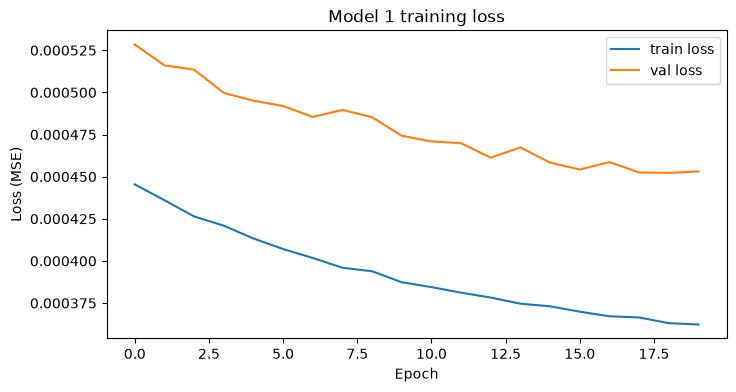

In [21]:
# Plot Model 1 training vs validation loss
plt.figure(figsize=(8, 4))
plt.plot(history1.history["loss"], label="train loss")
plt.plot(history1.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Model 1 training loss")
plt.legend()
plt.show()


#### Model 2 (deeper)

In [22]:
# Model 2: deeper LSTM autoencoder with stacked LSTM layers and dropout
model2 = Sequential([
    Input(shape=(1, num_features)),

    # Encoder: two LSTM layers (64 -> 32)
    LSTM(64, activation="relu", return_sequences=True),
    Dropout(0.2),
    LSTM(32, activation="relu"),

    # Bridge
    RepeatVector(1),

    # Decoder: two LSTM layers (32 -> 64)
    LSTM(32, activation="relu", return_sequences=True),
    Dropout(0.2),
    LSTM(64, activation="relu", return_sequences=True),

    # Output layer
    TimeDistributed(Dense(num_features))
])

model2.compile(optimizer="adam", loss="mse",jit_compile=False)
model2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 1, 64)          │        46,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 1, 32)          │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 1, 64)          │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 1, 118)         │         7,670 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,086 (390.96 KB)

 Trainable params: 100,086 (390.96 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# Train Model 2 (same idea, just a bigger network)
history2 = model2.fit(
    X_train_seq, X_train_seq,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    shuffle=True
)


Epoch 1/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0039 - val_loss: 0.0035
Epoch 2/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0037 - val_loss: 0.0033
Epoch 3/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0035 - val_loss: 0.0031
Epoch 4/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0033 - val_loss: 0.0029
Epoch 5/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.0031 - val_loss: 0.0026
Epoch 6/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0029 - val_loss: 0.0025
Epoch 7/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0028 - val_loss: 0.0024
Epoch 8/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0027 - val_loss: 0.0022
Epoch 9/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0026 - val_loss: 0.0022
Epoch 10/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0025 - val_loss: 0.0021
Epoch 11/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0024 - val_loss: 0.0020
Epoch 12/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 

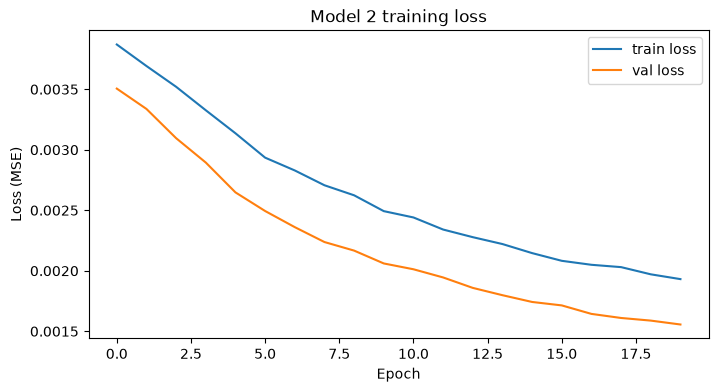

In [25]:
# Plot Model 2 training vs validation loss
plt.figure(figsize=(8, 4))
plt.plot(history2.history["loss"], label="train loss")
plt.plot(history2.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Model 2 training loss")
plt.legend()
plt.show()


### d) Reconstruction error and threshold

The reconstruction error for a row = the mean squared difference between the original row
and what the model rebuilt. Normal rows should have small errors, anomalies large errors.

**Threshold choice:** we take the normal training data, compute its reconstruction errors,
and set the threshold at the 95th percentile. The idea: about 95% of normal rows fall below
this line, so anything above it is unusual enough to call an anomaly.


In [26]:
# A small helper that returns the reconstruction error for every row
def reconstruction_error(model, X_seq):
    reconstructed = model.predict(X_seq, verbose=0)
    # mean squared error per row (average over timesteps and features)
    errors = np.mean(np.square(X_seq - reconstructed), axis=(1, 2))
    return errors


In [27]:
# Pick a threshold for each model using ONLY normal training data (95th percentile)
train_errors_1 = reconstruction_error(model1, X_train_seq)
threshold1 = np.percentile(train_errors_1, 95)
print("Model 1 threshold:", threshold1)

train_errors_2 = reconstruction_error(model2, X_train_seq)
threshold2 = np.percentile(train_errors_2, 95)
print("Model 2 threshold:", threshold2)


Model 1 threshold: 0.0013703553230710677
Model 2 threshold: 0.008847234135891328


In [28]:
# Compute reconstruction errors on the test set for both models
test_errors_1 = reconstruction_error(model1, X_test_seq)
test_errors_2 = reconstruction_error(model2, X_test_seq)

# Predict anomaly (1) if the error is above the threshold, else normal (0)
pred1 = (test_errors_1 > threshold1).astype(int)
pred2 = (test_errors_2 > threshold2).astype(int)

print("Model 1 flagged", np.sum(pred1), "anomalies out of", len(pred1))
print("Model 2 flagged", np.sum(pred2), "anomalies out of", len(pred2))


Model 1 flagged 2358 anomalies out of 5039
Model 2 flagged 2361 anomalies out of 5039


### e) Evaluation

We measure Precision, Recall, F1-score and ROC-AUC on the test set for both models.
- **Precision**: of the rows we flagged as anomaly, how many really were.
- **Recall**: of all real anomalies, how many we caught.
- **F1-score**: balance between precision and recall.
- **ROC-AUC**: how well the error score separates normal from anomaly (uses the raw error,
  not the 0/1 prediction).


In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

def evaluate(name, y_true, y_pred, error_scores):
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    # ROC-AUC uses the continuous error score (higher error = more likely anomaly)
    roc_auc = roc_auc_score(y_true, error_scores)
    return {
        "Model": name,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4),
    }

results = [
    evaluate("LSTM Model 1 (simple)", y_test, pred1, test_errors_1),
    evaluate("LSTM Model 2 (deeper)", y_test, pred2, test_errors_2),
]

results_df = pd.DataFrame(results).set_index("Model")
results_df


,Precision,Recall,F1-score,ROC-AUC
Model,,,,
LSTM Model 1 (simple),0.9432,0.9468,0.9450,0.9835
LSTM Model 2 (deeper),0.9445,0.9493,0.9469,0.9890


### f) Visualization

Two plots per model:
1. **Reconstruction error over time** (row index), with the threshold line. Points above
   the line are flagged as anomalies.
2. **Detected anomalies**, coloured by whether each row is actually normal or an anomaly,
   so we can see how well the threshold separates them.


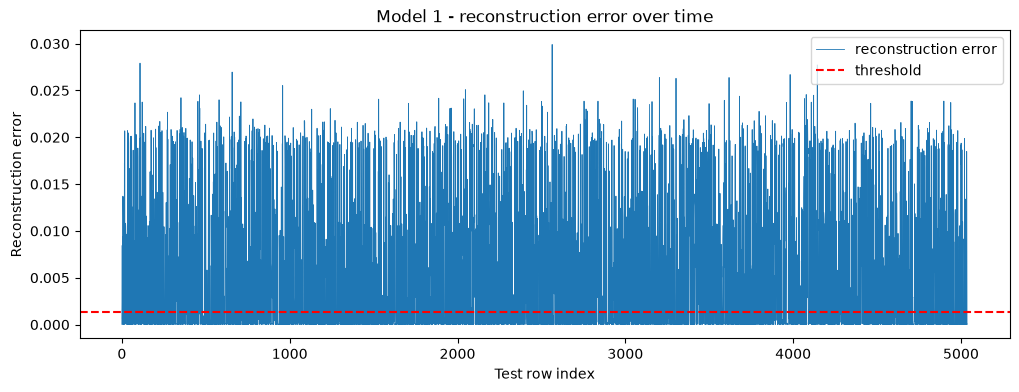

In [30]:
# Reconstruction error over time for Model 1
plt.figure(figsize=(12, 4))
plt.plot(test_errors_1, label="reconstruction error", linewidth=0.6)
plt.axhline(threshold1, color="red", linestyle="--", label="threshold")
plt.xlabel("Test row index")
plt.ylabel("Reconstruction error")
plt.title("Model 1 - reconstruction error over time")
plt.legend()
plt.show()


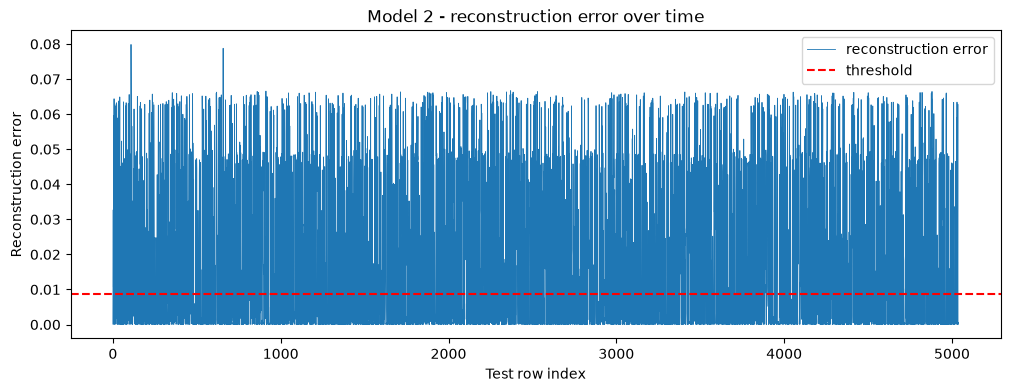

In [31]:
# Reconstruction error over time for Model 2
plt.figure(figsize=(12, 4))
plt.plot(test_errors_2, label="reconstruction error", linewidth=0.6)
plt.axhline(threshold2, color="red", linestyle="--", label="threshold")
plt.xlabel("Test row index")
plt.ylabel("Reconstruction error")
plt.title("Model 2 - reconstruction error over time")
plt.legend()
plt.show()


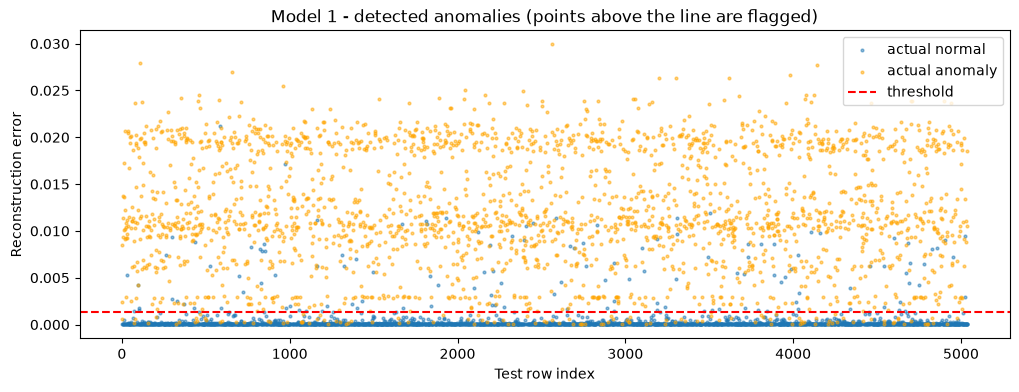

In [32]:
# Detected anomalies for Model 1: colour each test point by its TRUE label
plt.figure(figsize=(12, 4))
normal_idx = np.where(y_test == 0)[0]
anomaly_idx = np.where(y_test == 1)[0]
plt.scatter(normal_idx, test_errors_1[normal_idx], s=4, label="actual normal", alpha=0.5)
plt.scatter(anomaly_idx, test_errors_1[anomaly_idx], s=4, color="orange", label="actual anomaly", alpha=0.5)
plt.axhline(threshold1, color="red", linestyle="--", label="threshold")
plt.xlabel("Test row index")
plt.ylabel("Reconstruction error")
plt.title("Model 1 - detected anomalies (points above the line are flagged)")
plt.legend()
plt.show()


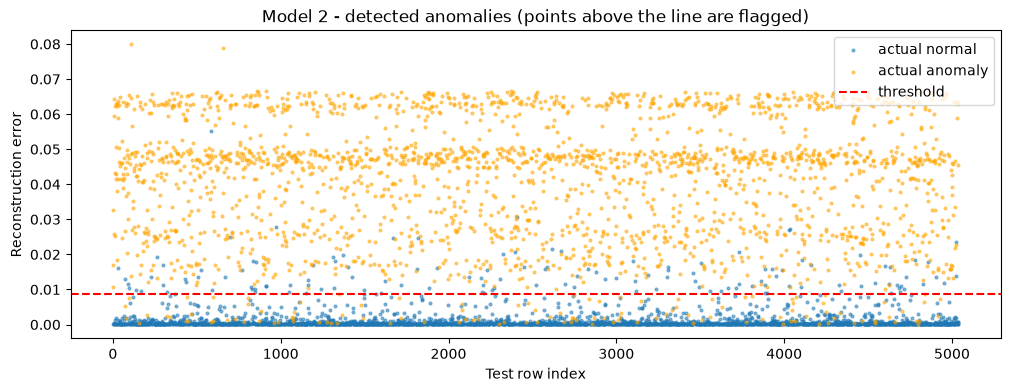

In [33]:
# Detected anomalies for Model 2
plt.figure(figsize=(12, 4))
plt.scatter(normal_idx, test_errors_2[normal_idx], s=4, label="actual normal", alpha=0.5)
plt.scatter(anomaly_idx, test_errors_2[anomaly_idx], s=4, color="orange", label="actual anomaly", alpha=0.5)
plt.axhline(threshold2, color="red", linestyle="--", label="threshold")
plt.xlabel("Test row index")
plt.ylabel("Reconstruction error")
plt.title("Model 2 - detected anomalies (points above the line are flagged)")
plt.legend()
plt.show()


## Question 2: Baseline Model Comparison

We use **Isolation Forest** as the baseline. We train it on
the same normal training data and evaluate it on the same test set with the same metrics,
so the comparison is fair.


In [ ]:
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(n_estimators=100, contamination=0.5, random_state=42)
iso_forest.fit(X_train_normal)

# Isolation Forest returns 1 for normal and -1 for anomaly. Convert to our 0/1 labels.
iso_raw = iso_forest.predict(X_test)
iso_pred = (iso_raw == -1).astype(int)

# For ROC-AUC we need a score where higher = more anomalous.
# score_samples returns higher values for normal points, so we flip the sign.
iso_scores = -iso_forest.score_samples(X_test)

print("Isolation Forest flagged", np.sum(iso_pred), "anomalies out of", len(iso_pred))


Isolation Forest flagged 3703 anomalies out of 5039


In [35]:
# Evaluate the baseline with the same metrics
baseline_result = evaluate("Isolation Forest (baseline)", y_test, iso_pred, iso_scores)
baseline_df = pd.DataFrame([baseline_result]).set_index("Model")
baseline_df


,Precision,Recall,F1-score,ROC-AUC
Model,,,,
Isolation Forest (baseline),0.6344,1.0,0.7763,0.9789


## Model Comparison

The table below puts all three models side by side on the same test set and metrics:
LSTM Model 1 vs LSTM Model 2 vs the Isolation Forest baseline.


In [36]:
# Combine all results into one comparison table
all_results = results + [baseline_result]
comparison_df = pd.DataFrame(all_results).set_index("Model")
print("Comparison of all models on the test set:")
comparison_df


Comparison of all models on the test set:


,Precision,Recall,F1-score,ROC-AUC
Model,,,,
LSTM Model 1 (simple),0.9432,0.9468,0.9450,0.9835
LSTM Model 2 (deeper),0.9445,0.9493,0.9469,0.9890
Isolation Forest (baseline),0.6344,1.0000,0.7763,0.9789


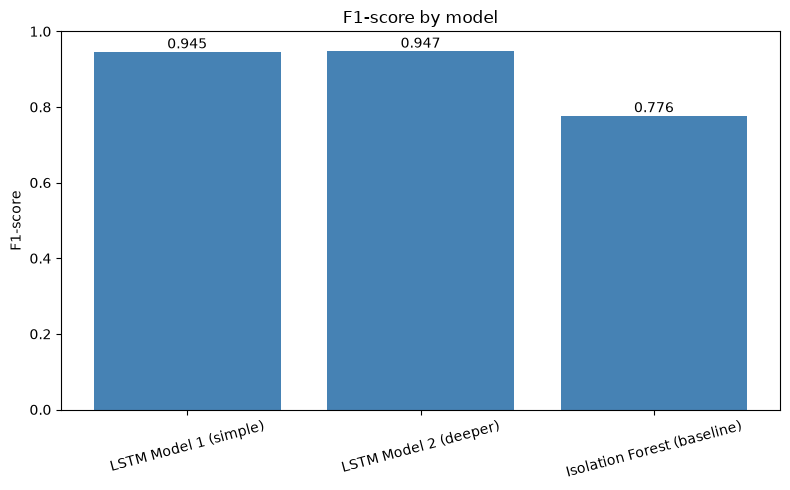

In [37]:
# Bar chart comparing F1-score across models
plt.figure(figsize=(8, 5))
plt.bar(comparison_df.index, comparison_df["F1-score"], color="steelblue")
plt.ylabel("F1-score")
plt.title("F1-score by model")
plt.xticks(rotation=15)
plt.ylim(0, 1)
for i, v in enumerate(comparison_df["F1-score"]):
    plt.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout()
plt.show()
